# Day 3 — Customer Feedback Analysis Using NLP
## Uber Eats Operational & Customer Intelligence System

**Objective:** Analyze customer reviews to understand sentiment and identify the major drivers of dissatisfaction.

### Day 3 deliverables
- Cleaned review dataset
- NLP preprocessing pipeline
- TF-IDF features and important words/phrases
- Sentiment classification model (Naive Bayes)
- Evaluation report: accuracy, precision, recall, F1-score and confusion matrix
- VADER comparison
- Sentiment insights and common complaint themes

> The data is synthetic. Treat conclusions as exploratory findings about this generated dataset, not verified facts about real Uber Eats customers.

In [1]:
import re
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 160)

DATA_DIR = Path("../data/synthetic")
OUTPUT_DIR = Path("../data/processed")
FIGURE_DIR = Path("../reports/figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Synthetic data folder exists:", DATA_DIR.exists())

Working directory: /home/nineleaps/uber-eats-intelligence/notebooks
Synthetic data folder exists: True


## 2. Load and inspect reviews



In [2]:
reviews = pd.read_csv(DATA_DIR / "reviews.csv")
print("Shape:", reviews.shape)
print("Columns:", reviews.columns.tolist())
display(reviews.head())

Shape: (7000, 7)
Columns: ['review_id', 'order_id', 'customer_id', 'restaurant_id', 'review_text', 'sentiment_label', 'review_rating']


,review_id,order_id,customer_id,restaurant_id,review_text,sentiment_label,review_rating
0,RV00001,O07010,C0803,R023,Delivery was late and food was cold,Negative,1
1,RV00002,O07056,C0388,R055,Order arrived late and packaging was damaged,Negative,1
2,RV00003,O07563,C0749,R069,Food was delicious and arrived on time,Positive,5
3,RV00004,O09444,C0087,R020,Order arrived late and packaging was damaged,Negative,1
4,RV00005,O00630,C0078,R031,"Food was okay, nothing special",Neutral,3


In [3]:
def find_column(columns, candidates):
    lookup = {str(c).strip().lower(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    # Allow common variations such as review_text or customer_review
    for c in columns:
        name = str(c).strip().lower()
        if any(candidate.lower() in name for candidate in candidates):
            return c
    return None

TEXT_COL = find_column(
    reviews.columns,
    ["review_text", "review", "feedback", "comment", "customer_review", "text"]
)
RATING_COL = find_column(
    reviews.columns,
    ["review_rating", "rating", "stars", "review_score"]
)
LABEL_COL = find_column(
    reviews.columns,
    ["sentiment", "sentiment_label", "label", "sentiment_class"]
)

print("Detected text column:", TEXT_COL)
print("Detected rating column:", RATING_COL)
print("Detected sentiment-label column:", LABEL_COL)

if TEXT_COL is None:
    raise ValueError(
        "Could not detect the review-text column. Set TEXT_COL manually "
        "to the exact column name printed above."
    )

Detected text column: review_text
Detected rating column: review_rating
Detected sentiment-label column: sentiment_label


## 3. Prepare a review analysis table


- Rating 1–2 → negative
- Rating 3 → neutral
- Rating 4–5 → positive



In [4]:
analysis = reviews.copy()
analysis[TEXT_COL] = analysis[TEXT_COL].fillna("").astype(str).str.strip()
analysis = analysis[analysis[TEXT_COL].ne("")].copy()

if LABEL_COL is not None:
    analysis["sentiment_label"] = analysis[LABEL_COL].astype(str).str.strip().str.lower()
    label_map = {
        "positive": "positive", "pos": "positive", "1": "positive",
        "negative": "negative", "neg": "negative", "-1": "negative",
        "neutral": "neutral", "neu": "neutral", "0": "neutral"
    }
    analysis["sentiment_label"] = analysis["sentiment_label"].map(
        lambda x: label_map.get(x, x)
    )
    valid_labels = {"positive", "negative", "neutral"}
    analysis.loc[~analysis["sentiment_label"].isin(valid_labels), "sentiment_label"] = np.nan

elif RATING_COL is not None:
    ratings = pd.to_numeric(analysis[RATING_COL], errors="coerce")
    analysis["sentiment_label"] = np.select(
        [ratings <= 2, ratings == 3, ratings >= 4],
        ["negative", "neutral", "positive"],
        default=None
    )
    analysis.loc[ratings.isna(), "sentiment_label"] = np.nan
else:
    analysis["sentiment_label"] = np.nan

print("Usable reviews:", len(analysis))
print("Missing/unknown labels:", analysis["sentiment_label"].isna().sum())
if analysis["sentiment_label"].notna().any():
    display(analysis["sentiment_label"].value_counts(dropna=False).to_frame("count"))
display(analysis[[TEXT_COL, "sentiment_label"]].head())

Usable reviews: 7000
Missing/unknown labels: 0


,count
sentiment_label,
negative,2373
positive,2353
neutral,2274


,review_text,sentiment_label
0,Delivery was late and food was cold,negative
1,Order arrived late and packaging was damaged,negative
2,Food was delicious and arrived on time,positive
3,Order arrived late and packaging was damaged,negative
4,"Food was okay, nothing special",neutral


## 4. Text cleaning: lowercasing, punctuation removal, tokenization, stop-word removal and lemmatization

For traditional bag-of-words and TF-IDF models, normalizing text reduces noise and combines variants of words. Stop-word removal can reduce very common words, but negations such as **not**, **no**, and **never** should be preserved because they can reverse sentiment.

This cell uses NLTK lemmatization if its resources are available. If not, it falls back to a lightweight tokenizer and stop-word list so the notebook can still run offline.

In [5]:
try:
    import nltk
    from nltk.stem import WordNetLemmatizer
    # Try local resources first; downloads may require internet access.
    try:
        lemmatizer = WordNetLemmatizer()
        lemmatizer.lemmatize("orders")
        NLTK_LEMMATIZATION_AVAILABLE = True
    except LookupError:
        NLTK_LEMMATIZATION_AVAILABLE = False
except ImportError:
    NLTK_LEMMATIZATION_AVAILABLE = False

stop_words = set(ENGLISH_STOP_WORDS)
# Preserve negation and contrast terms that matter for sentiment.
stop_words = stop_words - {"no", "not", "nor", "never", "but"}

if NLTK_LEMMATIZATION_AVAILABLE:
    lemmatizer = WordNetLemmatizer()
else:
    lemmatizer = None

def clean_review(text):
    text = str(text).lower()
    # Keep letters/numbers and spaces; remove punctuation/symbol noise.
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    tokens = re.findall(r"\b[a-z0-9]+\b", text)
    cleaned_tokens = []
    for token in tokens:
        if token in stop_words:
            continue
        if lemmatizer is not None and token.isalpha():
            try:
                token = lemmatizer.lemmatize(token)
            except LookupError:
                pass
        cleaned_tokens.append(token)
    return " ".join(cleaned_tokens)

analysis["cleaned_review"] = analysis[TEXT_COL].apply(clean_review)
analysis = analysis[analysis["cleaned_review"].str.strip().ne("")].copy()

display(analysis[[TEXT_COL, "cleaned_review"]].head(10))
print("NLTK lemmatization available:", NLTK_LEMMATIZATION_AVAILABLE)

,review_text,cleaned_review
0,Delivery was late and food was cold,delivery late food cold
1,Order arrived late and packaging was damaged,order arrived late packaging damaged
2,Food was delicious and arrived on time,food delicious arrived time
3,Order arrived late and packaging was damaged,order arrived late packaging damaged
4,"Food was okay, nothing special",food okay special
5,Delivery was late and food was cold,delivery late food cold
6,"Food was okay, nothing special",food okay special
7,"Food was okay, nothing special",food okay special
8,Average service and acceptable food,average service acceptable food
9,Average service and acceptable food,average service acceptable food


NLTK lemmatization available: False


## 5. Explore sentiment labels

This plot is meaningful when labels exist. If labels were derived from ratings, remember that the chart reflects rating-based proxy labels.

,review_count
sentiment_label,
negative,2373
positive,2353
neutral,2274


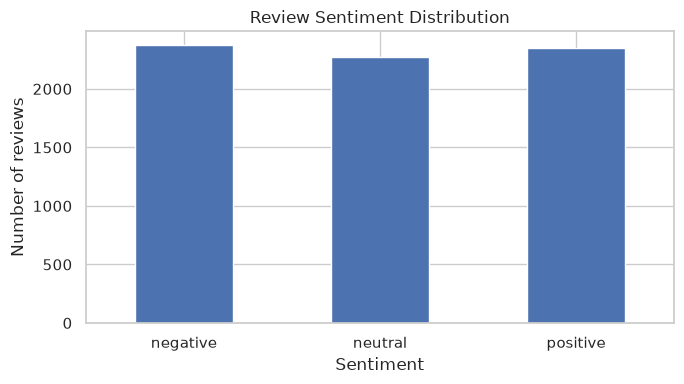

In [6]:
label_counts = analysis["sentiment_label"].value_counts(dropna=False)
display(label_counts.to_frame("review_count"))

plt.figure(figsize=(7, 4))
label_counts.reindex(["negative", "neutral", "positive"]).dropna().plot(
    kind="bar", rot=0
)
plt.title("Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "day3_sentiment_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. TF-IDF features and important words/phrases

TF-IDF assigns greater weight to terms that are informative within a document and less weight to terms that appear in many documents. Unigrams are single words; bigrams are two-word phrases.

,term,mean_tfidf
0,food,0.123767
1,delivery,0.088778
2,experience,0.072899
3,late,0.069020
4,arrived,0.067857
5,average,0.065886
6,order,0.062882
7,food okay,0.054461
8,okay special,0.054461
9,okay,0.054461


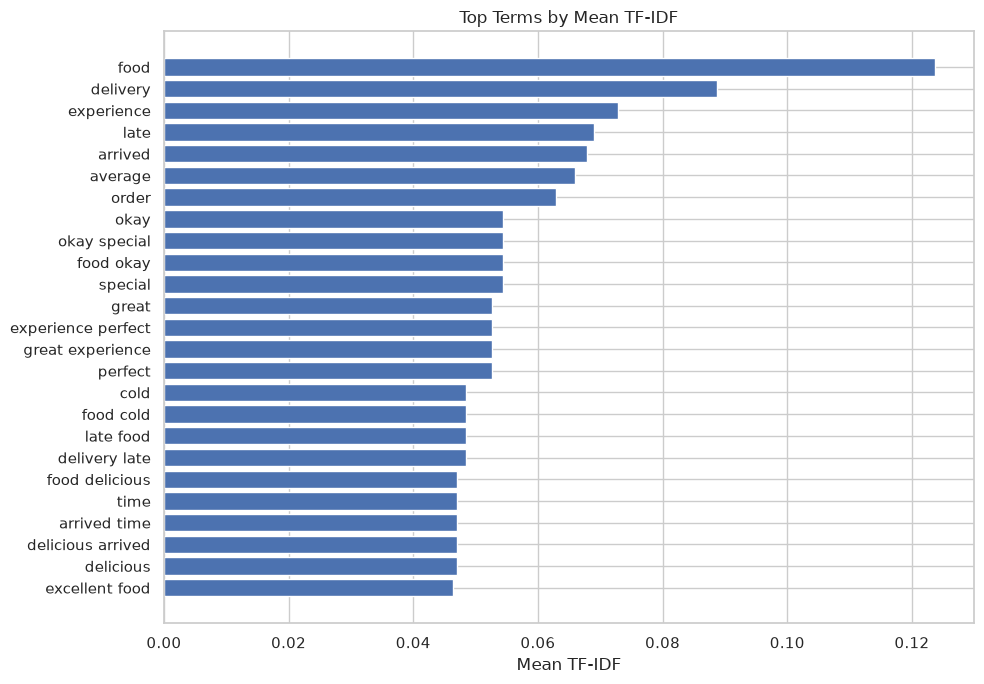

In [7]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000,
    min_df=1,
    sublinear_tf=True
)
X_tfidf_all = tfidf.fit_transform(analysis["cleaned_review"])
feature_names = np.array(tfidf.get_feature_names_out())

mean_tfidf = np.asarray(X_tfidf_all.mean(axis=0)).ravel()
top_tfidf_idx = mean_tfidf.argsort()[::-1][:25]
top_terms = pd.DataFrame({
    "term": feature_names[top_tfidf_idx],
    "mean_tfidf": mean_tfidf[top_tfidf_idx]
})
display(top_terms)

plt.figure(figsize=(10, 7))
plot_terms = top_terms.sort_values("mean_tfidf")
plt.barh(plot_terms["term"], plot_terms["mean_tfidf"])
plt.title("Top Terms by Mean TF-IDF")
plt.xlabel("Mean TF-IDF")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "day3_top_tfidf_terms.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Positive and negative keywords

When sentiment labels are available, compare term weights by sentiment. This is descriptive, not causal: a term may occur in several contexts, and rating-derived labels can make this comparison circular.

In [8]:
def top_terms_for_label(label, top_n=15):
    subset = analysis.loc[
        analysis["sentiment_label"].eq(label), "cleaned_review"
    ]
    if len(subset) == 0:
        return pd.DataFrame(columns=["term", "mean_tfidf"])
    matrix = tfidf.transform(subset)
    scores = np.asarray(matrix.mean(axis=0)).ravel()
    idx = scores.argsort()[::-1][:top_n]
    return pd.DataFrame({
        "term": feature_names[idx],
        "mean_tfidf": scores[idx]
    })

positive_terms = top_terms_for_label("positive")
negative_terms = top_terms_for_label("negative")

print("Terms common in positive reviews:")
display(positive_terms)

print("Terms common in negative reviews:")
display(negative_terms)

Terms common in positive reviews:


,term,mean_tfidf
0,perfect,0.156494
1,great,0.156494
2,experience perfect,0.156494
3,great experience,0.156494
4,time,0.139921
5,food delicious,0.139921
6,delicious arrived,0.139921
7,arrived time,0.139921
8,delicious,0.139921
9,excellent,0.137754


Terms common in negative reviews:


,term,mean_tfidf
0,late,0.203599
1,order,0.185493
2,late food,0.142948
3,delivery late,0.142948
4,food cold,0.142948
5,cold,0.142948
6,poor,0.120390
7,items order,0.120390
8,experience missing,0.120390
9,items,0.120390


## 8. Train/test split and Naive Bayes sentiment classifier

We use a TF-IDF + Multinomial Naive Bayes pipeline. A stratified split keeps class proportions similar in train and test sets where possible. The model is evaluated on a held-out test set.

**Evaluation caution:** If sentiment labels were generated from star ratings, the model is learning to predict rating-derived categories from review text. This is a useful capstone exercise, but it is not equivalent to evaluating against independently annotated sentiment.

In [9]:
labeled = analysis.dropna(subset=["sentiment_label"]).copy()
labeled = labeled[labeled["sentiment_label"].isin(["negative", "neutral", "positive"])]

class_counts = labeled["sentiment_label"].value_counts()
display(class_counts.to_frame("count"))

if len(labeled) < 10 or labeled["sentiment_label"].nunique() < 2:
    print(
        "Not enough labeled reviews/classes for a reliable supervised evaluation. "
        "Continue with TF-IDF and VADER insights; add verified labels if available."
    )
    model_available = False
else:
    model_available = True
    X_text = labeled["cleaned_review"]
    y = labeled["sentiment_label"]

    # Use stratification only if every class has at least 2 examples.
    stratify_y = y if y.value_counts().min() >= 2 else None

    X_train, X_test, y_train, y_test = train_test_split(
        X_text, y,
        test_size=0.25,
        random_state=42,
        stratify=stratify_y
    )

    sentiment_model = Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=5000,
            min_df=1,
            sublinear_tf=True
        )),
        ("classifier", MultinomialNB())
    ])

    sentiment_model.fit(X_train, y_train)
    y_pred = sentiment_model.predict(X_test)

    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Precision (macro):", round(precision_score(y_test, y_pred, average="macro", zero_division=0), 4))
    print("Recall (macro):", round(recall_score(y_test, y_pred, average="macro", zero_division=0), 4))
    print("F1-score (macro):", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0))

,count
sentiment_label,
negative,2373
positive,2353
neutral,2274


Accuracy: 1.0
Precision (macro): 1.0
Recall (macro): 1.0
F1-score (macro): 1.0

Classification report:
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00       593
     neutral       1.00      1.00      1.00       569
    positive       1.00      1.00      1.00       588

    accuracy                           1.00      1750
   macro avg       1.00      1.00      1.00      1750
weighted avg       1.00      1.00      1.00      1750



## 9. Confusion matrix

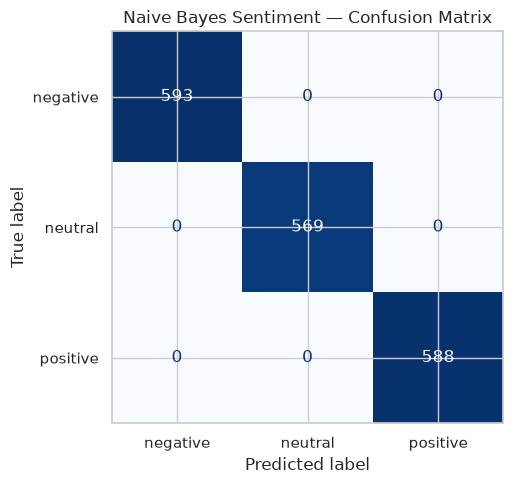

In [10]:
if model_available:
    class_order = [c for c in ["negative", "neutral", "positive"] if c in set(y_test) | set(y_pred)]
    cm = confusion_matrix(y_test, y_pred, labels=class_order)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_order)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    plt.title("Naive Bayes Sentiment — Confusion Matrix")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "day3_confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Confusion matrix skipped because supervised model evaluation was not available.")

## 10. VADER sentiment analysis

VADER is a rule/lexicon-based model designed for short, informal text and is sensitive to punctuation, capitalization, intensifiers and emojis. It can complement the traditional ML model.

We try NLTK's VADER implementation. If its lexicon is not installed, the cell attempts a download. If the environment is offline, it reports that VADER is unavailable rather than stopping the whole notebook.

In [11]:
vader_available = False
try:
    import nltk
    from nltk.sentiment import SentimentIntensityAnalyzer
    try:
        vader = SentimentIntensityAnalyzer()
    except LookupError:
        try:
            nltk.download("vader_lexicon", quiet=True)
            vader = SentimentIntensityAnalyzer()
        except Exception:
            vader = None
    vader_available = vader is not None
except Exception:
    vader = None

def vader_label(text):
    scores = vader.polarity_scores(str(text))
    compound = scores["compound"]
    if compound >= 0.05:
        label = "positive"
    elif compound <= -0.05:
        label = "negative"
    else:
        label = "neutral"
    return pd.Series({
        "vader_neg": scores["neg"],
        "vader_neu": scores["neu"],
        "vader_pos": scores["pos"],
        "vader_compound": compound,
        "vader_sentiment": label
    })

if vader_available:
    vader_scores = analysis[TEXT_COL].apply(vader_label)
    analysis = pd.concat([analysis, vader_scores], axis=1)
    display(analysis[[TEXT_COL, "vader_compound", "vader_sentiment"]].head(10))
else:
    print(
        "VADER lexicon unavailable. If internet access is available, run "
        "`import nltk; nltk.download('vader_lexicon')` and rerun this section."
    )

,review_text,vader_compound,vader_sentiment
0,Delivery was late and food was cold,0.0000,neutral
1,Order arrived late and packaging was damaged,-0.4404,negative
2,Food was delicious and arrived on time,0.5719,positive
3,Order arrived late and packaging was damaged,-0.4404,negative
4,"Food was okay, nothing special",-0.0920,negative
5,Delivery was late and food was cold,0.0000,neutral
6,"Food was okay, nothing special",-0.0920,negative
7,"Food was okay, nothing special",-0.0920,negative
8,Average service and acceptable food,0.3182,positive
9,Average service and acceptable food,0.3182,positive


## 11. Compare Naive Bayes and VADER

The comparison uses the same held-out examples where the trained model is available. Treat the comparison carefully if the reference labels were derived from ratings rather than human sentiment annotations.

In [12]:
if vader_available:
    if model_available:
        comparison = labeled.loc[X_test.index, [TEXT_COL, "sentiment_label"]].copy()
        comparison["naive_bayes_sentiment"] = y_pred
        comparison["vader_sentiment"] = analysis.loc[X_test.index, "vader_sentiment"]
        print("Naive Bayes vs reference labels — macro F1:",
              round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))
        print("VADER vs reference labels — accuracy:",
              round(accuracy_score(y_test, comparison["vader_sentiment"]), 4))
        print("VADER vs reference labels — macro F1:",
              round(f1_score(y_test, comparison["vader_sentiment"], average="macro", zero_division=0), 4))
        display(comparison.head(15))
    else:
        print("VADER sentiment distribution:")
        display(analysis["vader_sentiment"].value_counts().to_frame("count"))
else:
    print("Comparison skipped because VADER is unavailable.")

Naive Bayes vs reference labels — macro F1: 1.0
VADER vs reference labels — accuracy: 0.5669
VADER vs reference labels — macro F1: 0.4784


,review_text,sentiment_label,naive_bayes_sentiment,vader_sentiment
1490,"Great experience, everything was perfect",positive,positive,positive
2468,"Great experience, everything was perfect",positive,positive,positive
199,Average service and acceptable food,neutral,neutral,positive
2780,Food was delicious and arrived on time,positive,positive,positive
1669,"Food was okay, nothing special",neutral,neutral,negative
4827,Average service and acceptable food,neutral,neutral,positive
6192,Average service and acceptable food,neutral,neutral,positive
252,"Poor experience, missing items from my order",negative,negative,negative
5597,Excellent food and very quick delivery,positive,positive,positive
5785,Delivery was fine but the food was average,neutral,neutral,positive


## 12. Identify major complaint themes

This section extracts the most frequent terms and bigrams in negative reviews. It is a lightweight theme-discovery approach, not a full topic model. Inspect the terms in context before naming a complaint category.

,term_or_phrase,mean_tfidf
0,late,0.165057
1,order,0.157282
2,cold,0.128898
3,food,0.128898
4,food cold,0.128898
5,late food,0.128898
6,delivery late,0.128898
7,delivery,0.128898
8,items order,0.118813
9,experience missing,0.118813


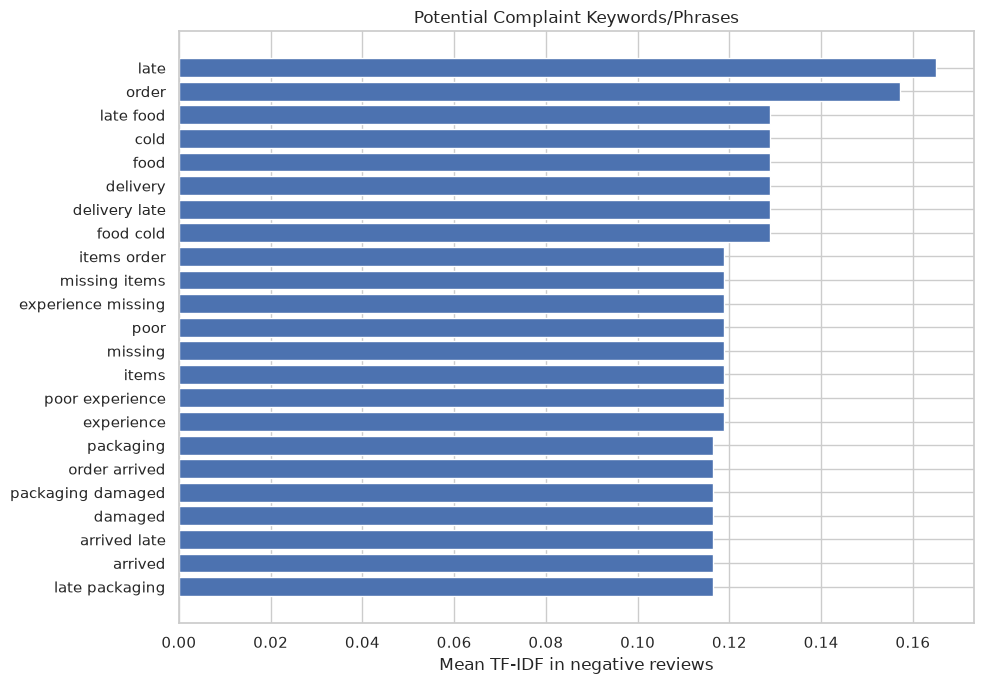

In [13]:
negative_reviews = analysis.loc[
    analysis["sentiment_label"].eq("negative"), "cleaned_review"
]

if len(negative_reviews) == 0 and vader_available:
    negative_reviews = analysis.loc[
        analysis["vader_sentiment"].eq("negative"), "cleaned_review"
    ]

if len(negative_reviews) > 0:
    complaint_vectorizer = TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=3000,
        min_df=1,
        sublinear_tf=True
    )
    complaint_matrix = complaint_vectorizer.fit_transform(negative_reviews)
    complaint_terms = np.array(complaint_vectorizer.get_feature_names_out())
    complaint_scores = np.asarray(complaint_matrix.mean(axis=0)).ravel()
    idx = complaint_scores.argsort()[::-1][:25]
    complaint_keywords = pd.DataFrame({
        "term_or_phrase": complaint_terms[idx],
        "mean_tfidf": complaint_scores[idx]
    })
    display(complaint_keywords)

    plt.figure(figsize=(10, 7))
    plot_complaints = complaint_keywords.sort_values("mean_tfidf")
    plt.barh(plot_complaints["term_or_phrase"], plot_complaints["mean_tfidf"])
    plt.title("Potential Complaint Keywords/Phrases")
    plt.xlabel("Mean TF-IDF in negative reviews")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "day3_complaint_keywords.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    complaint_keywords = pd.DataFrame(columns=["term_or_phrase", "mean_tfidf"])
    print("No negative reviews were identified from available labels/scores.")

## 13. Save the cleaned dataset and model evaluation report

In [14]:
# Save cleaned review data, including any available VADER scores.
cleaned_output = OUTPUT_DIR / "cleaned_reviews.csv"
analysis.to_csv(cleaned_output, index=False)
print("Saved:", cleaned_output)

# Save sentiment model metrics/report if a supervised model was trained.
report_lines = [
    "# Day 3 — NLP Sentiment Analysis Report",
    "",
    f"- Reviews analyzed: {len(analysis)}",
    f"- Review text column: `{TEXT_COL}`",
    f"- Rating column: `{RATING_COL}`",
    f"- Existing label column: `{LABEL_COL}`",
    f"- NLTK lemmatization available: {NLTK_LEMMATIZATION_AVAILABLE}",
    f"- VADER available: {vader_available}",
    "",
    "## Sentiment label distribution",
    analysis["sentiment_label"].value_counts(dropna=False).to_string(),
    ""
]

if model_available:
    report_lines += [
        "## Naive Bayes evaluation",
        f"- Accuracy: {accuracy_score(y_test, y_pred):.4f}",
        f"- Macro precision: {precision_score(y_test, y_pred, average='macro', zero_division=0):.4f}",
        f"- Macro recall: {recall_score(y_test, y_pred, average='macro', zero_division=0):.4f}",
        f"- Macro F1-score: {f1_score(y_test, y_pred, average='macro', zero_division=0):.4f}",
        "",
        "```text",
        classification_report(y_test, y_pred, zero_division=0),
        "```",
        ""
    ]

if vader_available:
    report_lines += [
        "## VADER sentiment distribution",
        analysis["vader_sentiment"].value_counts().to_string(),
        ""
    ]

report_lines += [
    "## Interpretation notes",
    "- Sentiment labels derived from ratings are proxy labels, not human-annotated sentiment.",
    "- TF-IDF terms and complaint keywords require manual contextual review.",
    "- The data is synthetic and does not establish real-world Uber Eats customer behavior.",
    ""
]

report_path = OUTPUT_DIR / "day3_nlp_evaluation_report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print("Saved:", report_path)

Saved: ../data/processed/cleaned_reviews.csv
Saved: ../data/processed/day3_nlp_evaluation_report.md


## 14. Final business insights checklist

Use the actual outputs above to complete this section. Do not invent complaint counts or model scores.

- Which sentiment is most common?
- What words and phrases appear most often in negative reviews?
- Are common complaints related to delivery delay, food quality, missing items, order accuracy, packaging, or customer support? Only use themes supported by the generated review text.
- How does the Naive Bayes model compare with VADER?
- Are the labels genuine sentiment labels or proxies derived from ratings?
- What are the limitations of synthetic reviews and small datasets?

### Suggested business actions (only if supported by findings)
- Investigate recurring delivery-delay complaints.
- Improve restaurant preparation-time estimates and delivery coordination.
- Monitor order accuracy and missing-item feedback.
- Use sentiment trends as an operational monitoring signal, not as the sole basis for decisions.

## 15. Save and version-control Day 3

Save this notebook, then from the repository root run:

```bash
git add notebooks/03_customer_feedback_nlp.ipynb data/processed/ reports/figures/
git commit -m "Implement Day 3 customer feedback NLP analysis"
git push
```